# Sentiment Model Comparison Dashboard

This notebook compares the classical TF-IDF + Logistic Regression model with the fine-tuned DistilBERT model. It uses saved evaluation artifacts and does not retrain either model.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'artifacts').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.evaluate_models import evaluate_models

comparison = evaluate_models(
    PROJECT_ROOT / 'artifacts/ml/ml_metrics.json',
    PROJECT_ROOT / 'artifacts/dl/dl_metrics.json',
    PROJECT_ROOT / 'artifacts/evaluation',
)
comparison['summary']

2026-06-19 21:12:10,701 | INFO | src.evaluation.evaluate_models | Saved model comparison artifacts to D:\Projects\OOP-tech\artifacts\evaluation


{'ml_test_macro_f1': 0.497451963241437,
 'dl_test_macro_f1': 0.6750261233019854,
 'absolute_macro_f1_gain': 0.17757416006054844,
 'relative_macro_f1_gain_percent': 35.69674525022696,
 'recommended_model': 'DistilBERT',
 'recommendation_reason': 'DistilBERT provides a substantial macro-F1 improvement while retaining practical GPU inference latency. Classical ML remains the lightweight fallback.'}

## Dataset Summary

The curated dataset combines 400 TweetEval examples and 400 Amazon review examples. The same fixed train, validation, and test splits are used for both models, making the comparison fair.

In [2]:
dataset = pd.read_csv(PROJECT_ROOT / 'data/processed/curated_sentiment_dataset.csv')
dataset_summary = pd.DataFrame({
    'Statistic': ['Total rows', 'TweetEval rows', 'Amazon rows', 'Negative', 'Neutral', 'Positive'],
    'Value': [
        len(dataset),
        int((dataset['source'] == 'tweet_eval').sum()),
        int((dataset['source'] == 'amazon_reviews').sum()),
        int((dataset['sentiment'] == 'negative').sum()),
        int((dataset['sentiment'] == 'neutral').sum()),
        int((dataset['sentiment'] == 'positive').sum()),
    ],
})
dataset_summary

,Statistic,Value
0,Total rows,800
1,TweetEval rows,400
2,Amazon rows,400
3,Negative,268
4,Neutral,266
5,Positive,266


## Model Configurations

**Classical ML:** TF-IDF features, Logistic Regression, and GridSearchCV optimized for macro F1.

**Deep Learning:** `distilbert-base-uncased` fine-tuned with a custom PyTorch loop, AdamW, linear scheduling, mixed precision, gradient clipping, and validation macro-F1 checkpoint selection.

## Overall Test Performance

In [3]:
overall = pd.read_csv(PROJECT_ROOT / 'artifacts/evaluation/overall_metrics.csv')
overall.round(4)

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Classical ML,0.5000,0.4965,0.5000,0.4975,0.4975
1,DistilBERT,0.6917,0.6803,0.6917,0.6750,0.6750


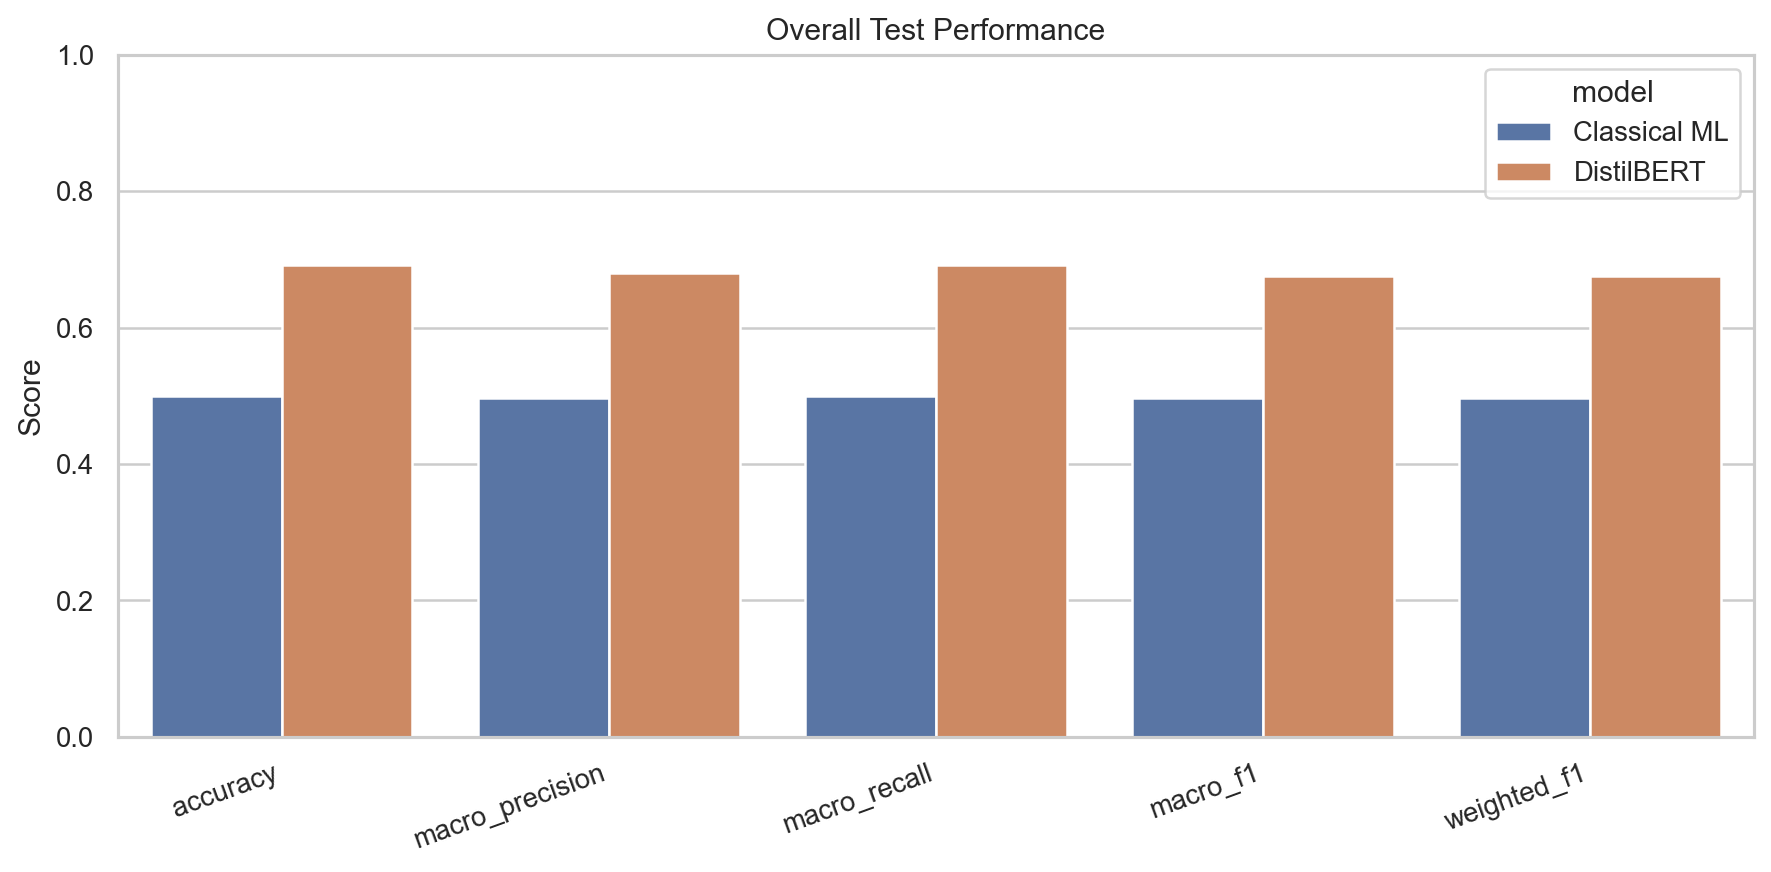

In [4]:
display(Image(filename=str(PROJECT_ROOT / 'artifacts/evaluation/overall_test_metrics.png')))

DistilBERT improves test accuracy from **0.5000** to **0.6917** and macro F1 from **0.4975** to **0.6750**. The absolute macro-F1 gain is **0.1775**, equivalent to a relative improvement of approximately **35.7%** over the classical baseline.

## Per-Class Performance

In [5]:
per_class = pd.read_csv(PROJECT_ROOT / 'artifacts/evaluation/per_class_metrics.csv')
per_class.round(4)

,model,label,precision,recall,f1,support
0,Classical ML,negative,0.5500,0.550,0.5500,40
1,Classical ML,neutral,0.4167,0.375,0.3947,40
2,Classical ML,positive,0.5227,0.575,0.5476,40
3,DistilBERT,negative,0.7021,0.825,0.7586,40
4,DistilBERT,neutral,0.6154,0.400,0.4848,40
5,DistilBERT,positive,0.7234,0.850,0.7816,40


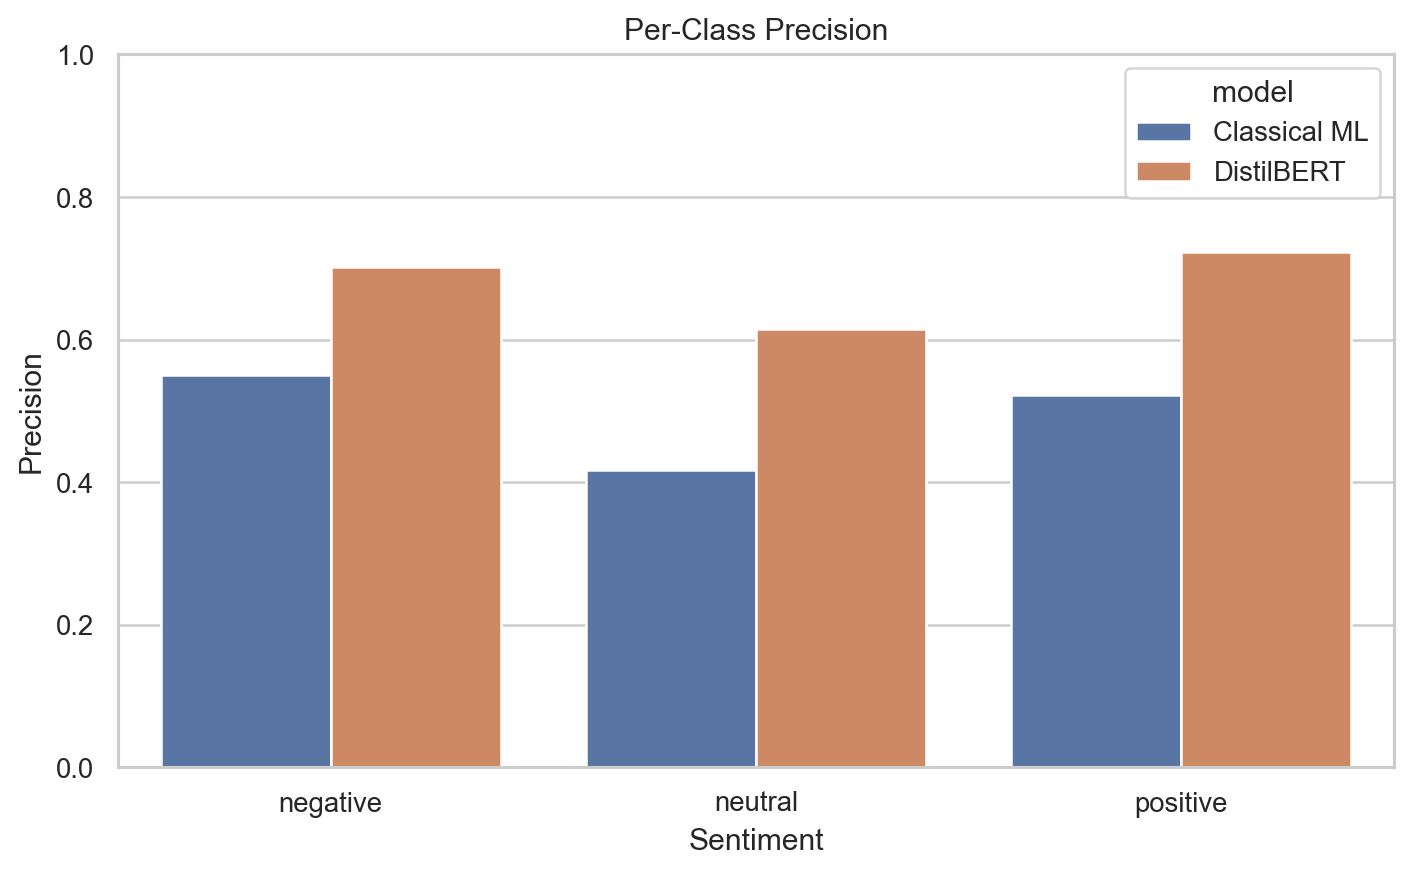

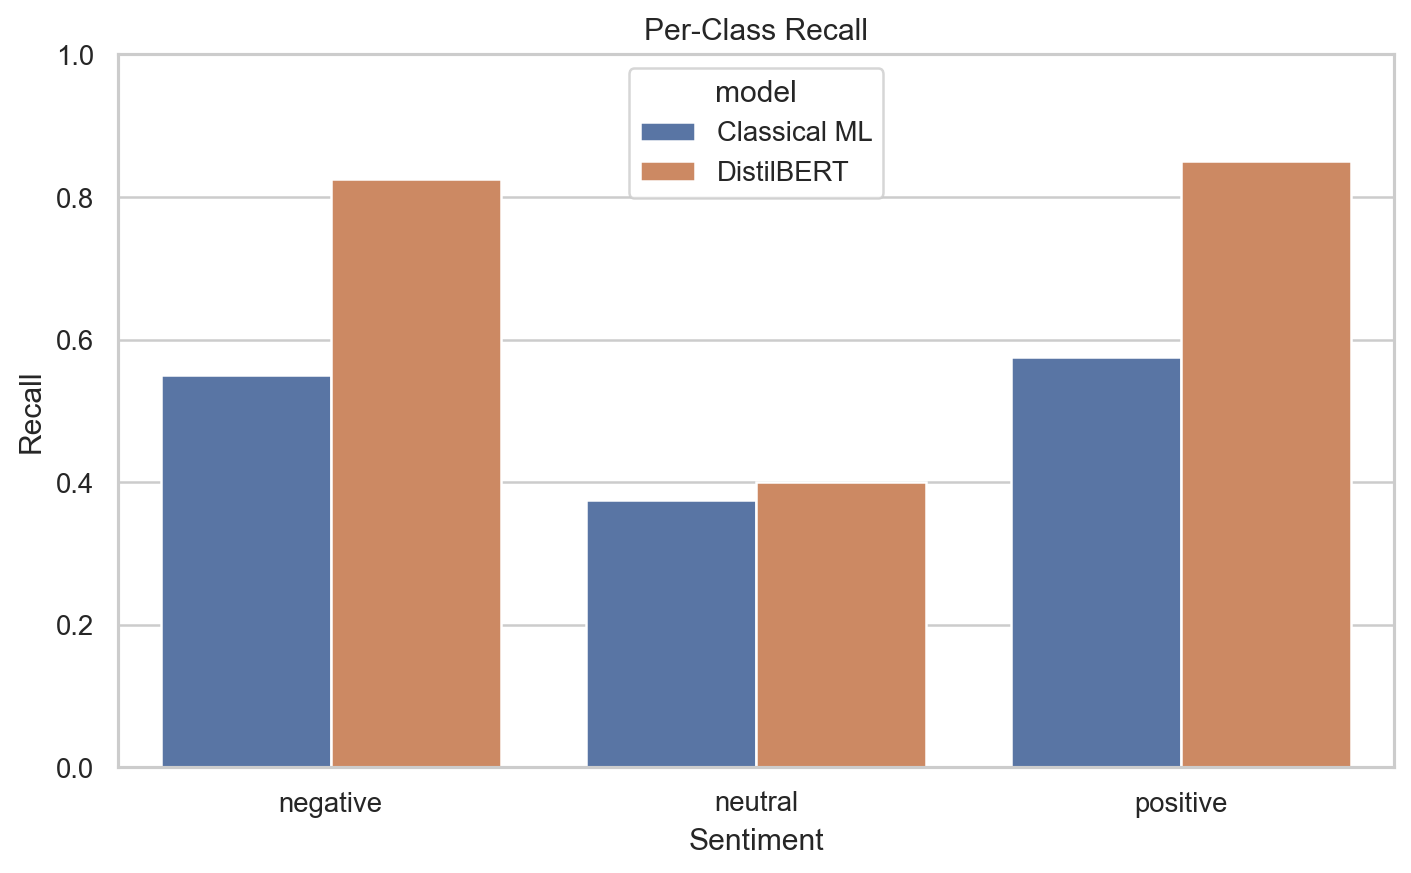

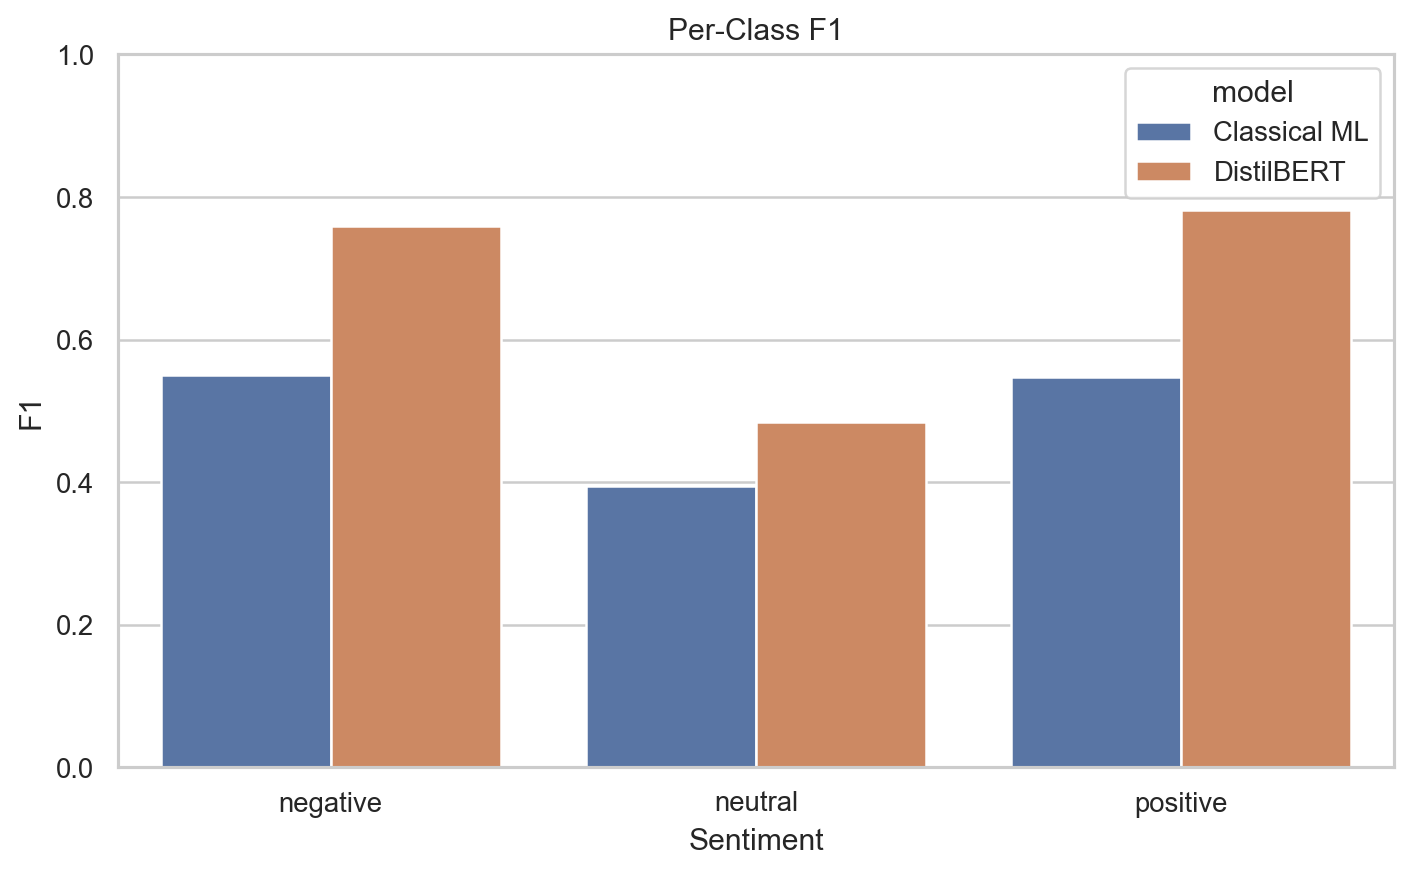

In [6]:
for chart in ['per_class_precision.png', 'per_class_recall.png', 'per_class_f1.png']:
    display(Image(filename=str(PROJECT_ROOT / 'artifacts/evaluation' / chart)))

DistilBERT provides its largest gains on negative and positive sentiment. Neutral sentiment remains the hardest class for both models: its F1 rises from **0.3947** to **0.4848**, but mixed-opinion and weakly subjective examples are still frequently confused with negative or positive sentiment.

## Confusion Matrices

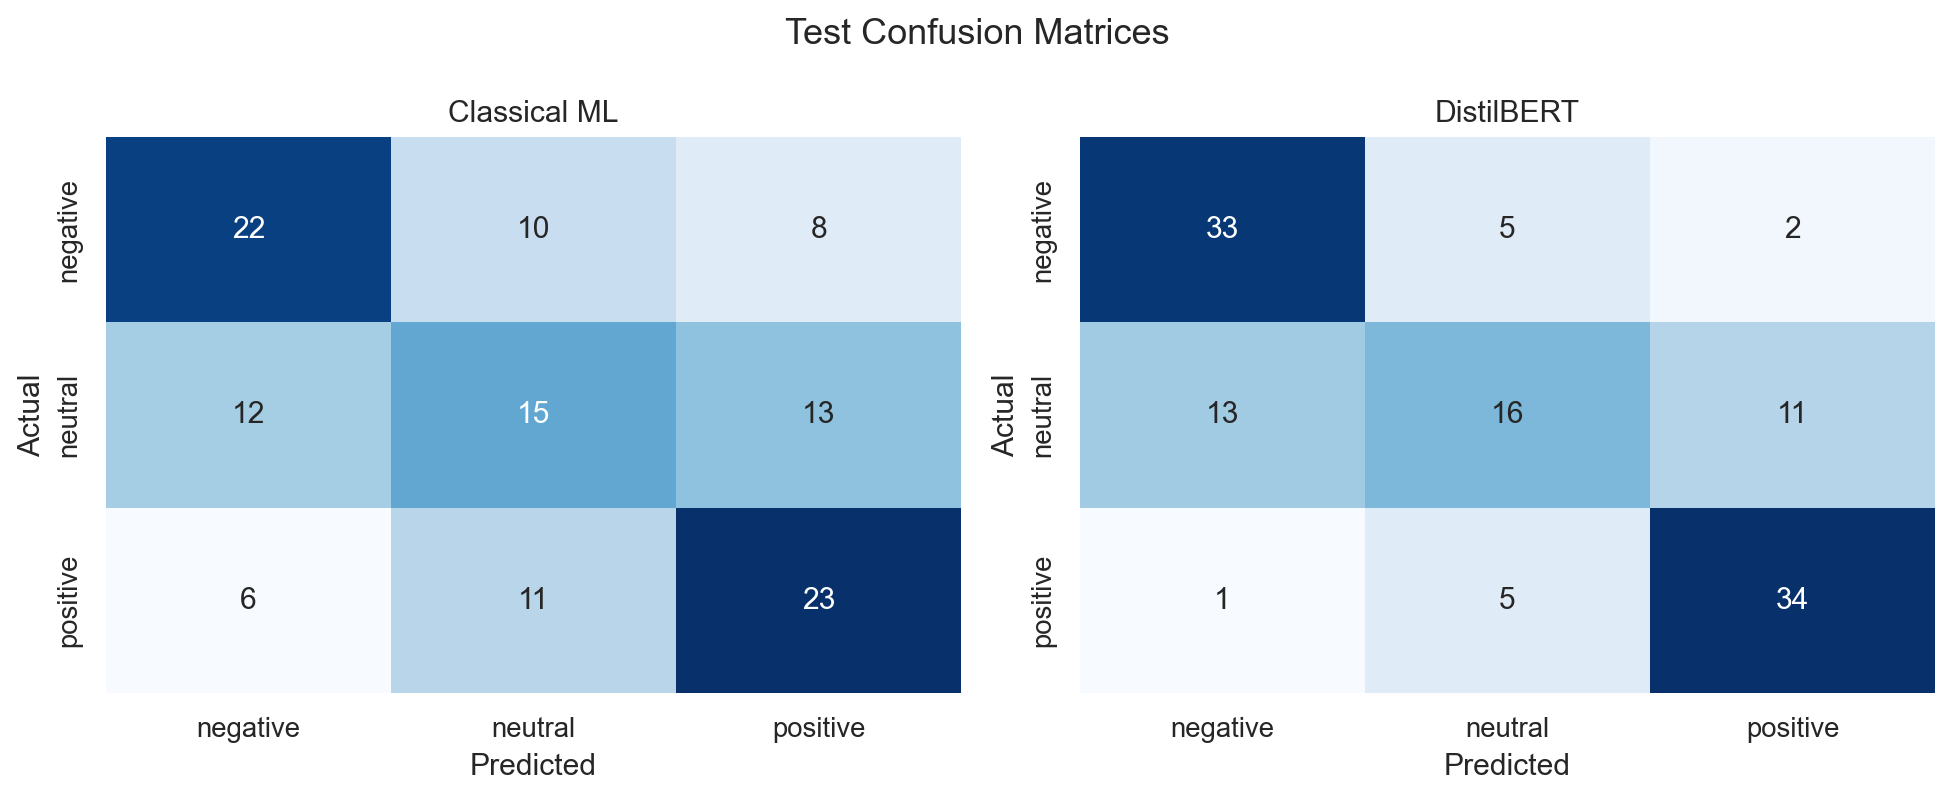

In [7]:
display(Image(filename=str(PROJECT_ROOT / 'artifacts/evaluation/confusion_matrices.png')))

The classical model correctly identifies 22 negative, 15 neutral, and 23 positive examples. DistilBERT increases these counts to 33 negative, 16 neutral, and 34 positive examples. Most remaining DistilBERT errors involve neutral examples crossing into an opinionated class.

## Efficiency Comparison

In [8]:
operational = pd.read_csv(PROJECT_ROOT / 'artifacts/evaluation/operational_metrics.csv')
operational.round(4)

,model,training_time_seconds,inference_time_ms_per_sample,model_size_mb
0,Classical ML,5.6093,0.0209,0.0667
1,DistilBERT,216.8941,11.9451,256.3295


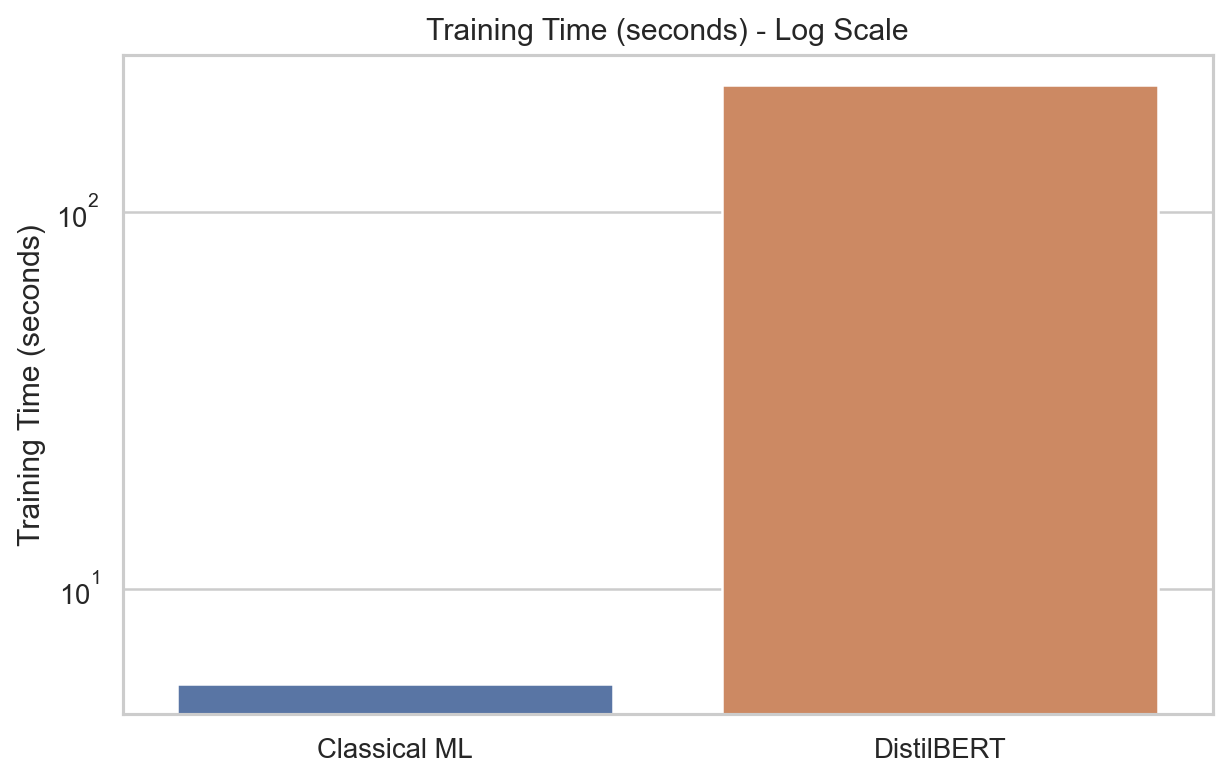

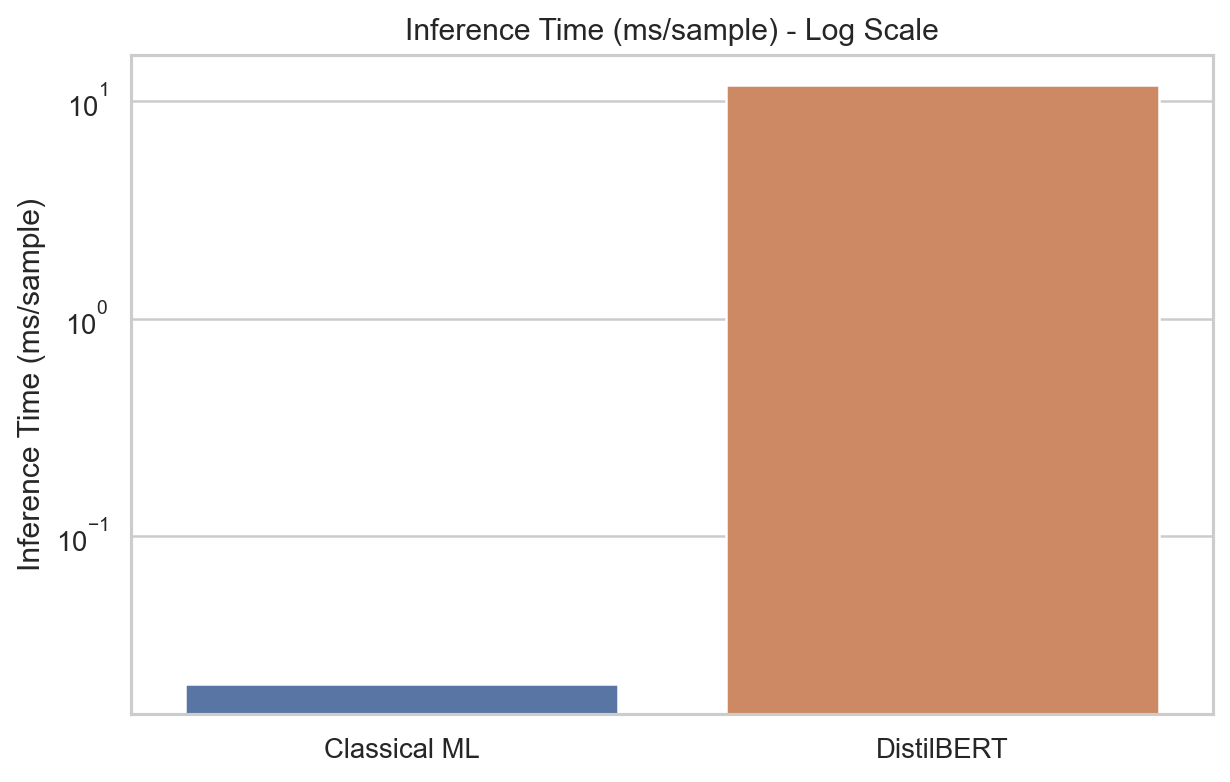

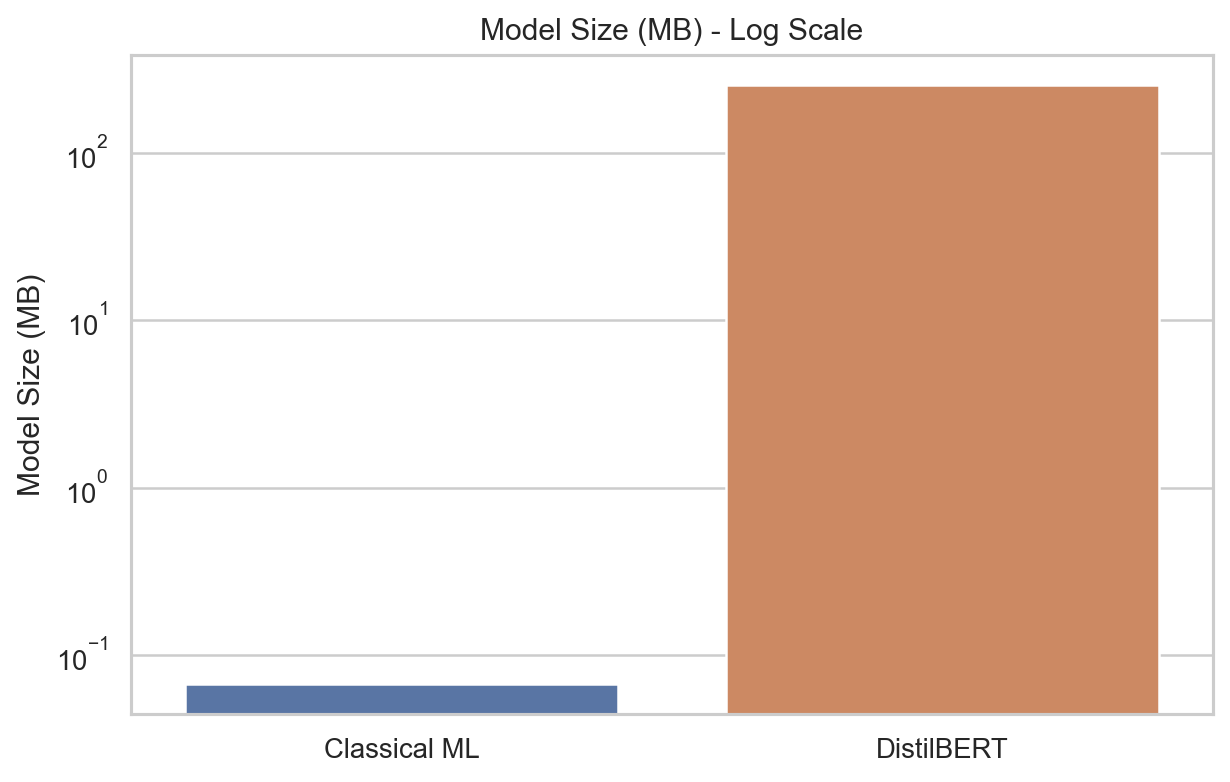

In [9]:
for chart in ['training_time.png', 'inference_speed.png', 'model_size.png']:
    display(Image(filename=str(PROJECT_ROOT / 'artifacts/evaluation' / chart)))

The classical model is dramatically smaller and faster: approximately **0.067 MB** and **0.021 ms/sample**, compared with DistilBERT at approximately **256.33 MB** and **11.95 ms/sample** on the available GPU. This is the main deployment tradeoff.

## DistilBERT Training History

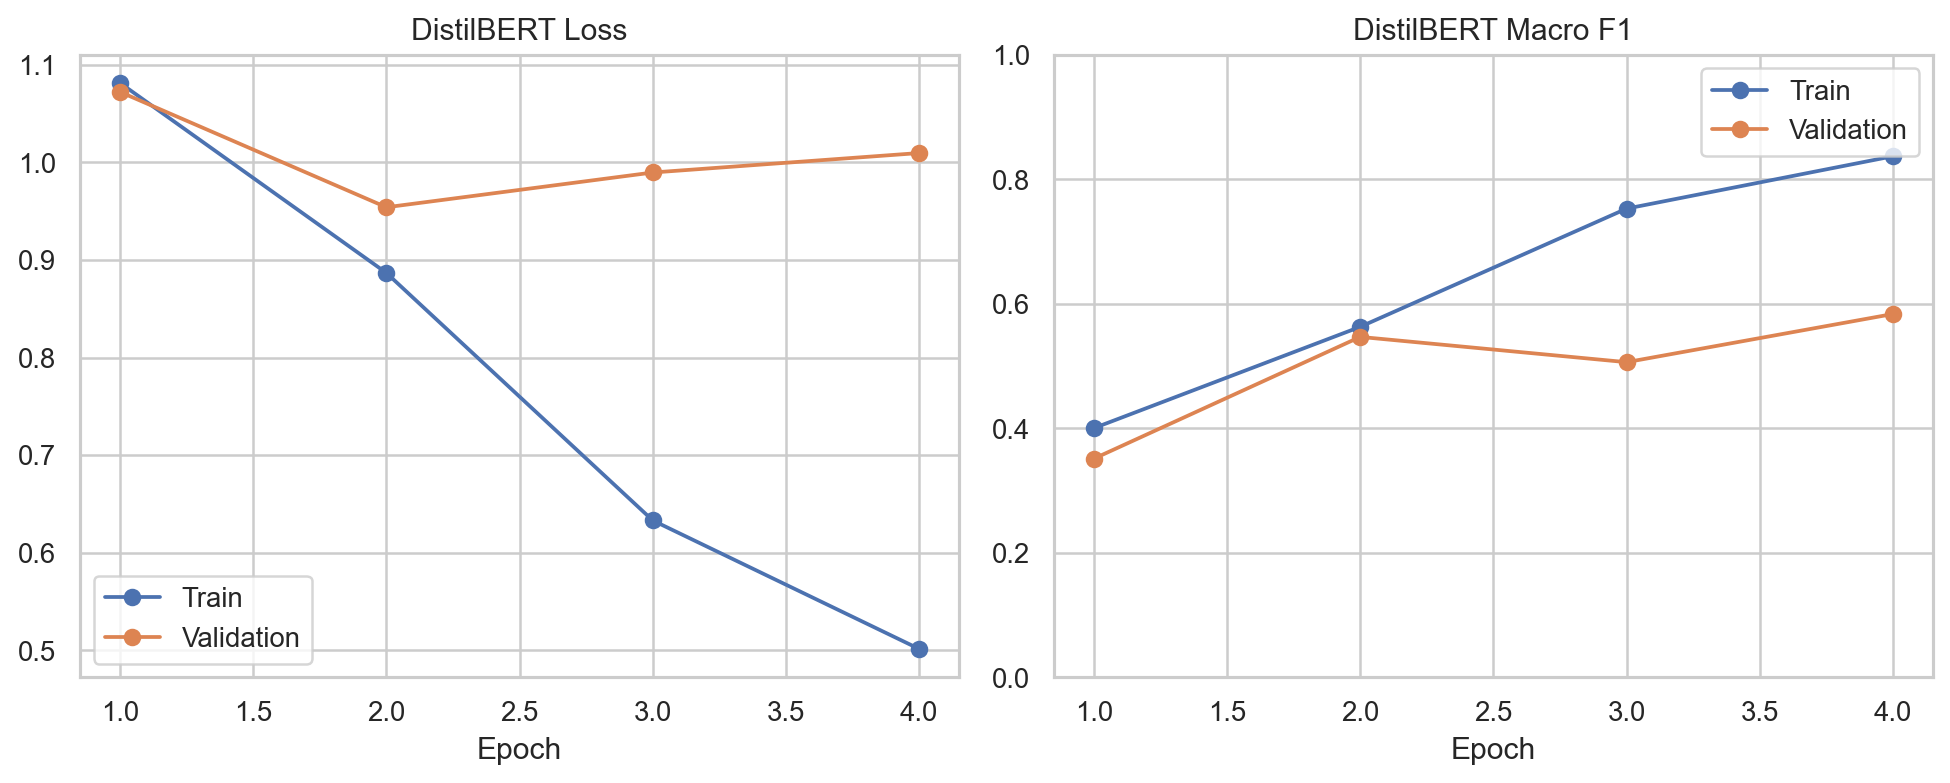

In [10]:
display(Image(filename=str(PROJECT_ROOT / 'artifacts/evaluation/distilbert_training_history.png')))

Training macro F1 increases steadily across four epochs. Validation performance fluctuates because the validation set contains only 120 examples, but epoch 4 produces the best validation macro F1 and is therefore selected without using the test set.

## Deployment Recommendation

**Deploy DistilBERT as the primary sentiment model.** Its 35.7% relative macro-F1 improvement and substantially stronger negative/positive recall justify the larger artifact for this evaluation. Its measured GPU latency remains practical for an online API.

Keep the classical ML model as a low-resource fallback. It is appropriate for CPU-only environments, high-throughput workloads, or degraded-service operation where model size and latency matter more than predictive quality.

## Final Conclusion

The transformer is the stronger production-quality classifier for this curated cross-domain dataset. The experiment also demonstrates that neutral sentiment is the central remaining challenge. Future improvements should prioritize additional manually reviewed neutral examples and targeted error analysis rather than tuning against the held-out test set.